# HMS Classic ML Models (2024–2025)

Predict **`dep_or_anx`** on cleaned **2024–2025** Healthy Minds Study data using **7 scikit-learn / gradient-boosting models**.

| | |
|---|---|
| **Target** | `dep_or_anx` |
| **Inputs** | 25 features (same as DL notebook; no `gender_nonbin` / `gender_trans`) |
| **Baselines** | Logistic Regression, Random Forest |
| **New models** | XGBoost, LightGBM, CatBoost, Extra Trees, HistGradientBoosting |

In [1]:
%pip install -q xgboost lightgbm catboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Setup & configuration

In [2]:
import random
import subprocess
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

try:
    from catboost import CatBoostClassifier
    from lightgbm import LGBMClassifier
    from xgboost import XGBClassifier
except ModuleNotFoundError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "xgboost", "lightgbm", "catboost", "-q"
    ])
    from catboost import CatBoostClassifier
    from lightgbm import LGBMClassifier
    from xgboost import XGBClassifier

from sklearn.ensemble import (
    ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    RocCurveDisplay, accuracy_score, classification_report, f1_score, roc_auc_score
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = Path(".").resolve()
OUTPUT_DIR = DATA_DIR / "exploration_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

TARGET = "dep_or_anx"
FEATURES = [
    "age", "gender_male", "gender_female",
    "international", "fincur", "finpast", "food_worry",
    "sleep_wknight", "sleep_wkend", "exerc",
    "belong1", "belong2", "lonely", "aca_impa", "flourish", "positiveMH",
    "sub_any", "binge1pl", "smok_cig",
    "discrim_race", "discrim_gender", "discrim_sexual",
    "inst_type", "inst_size", "inst_public",
]

print(f"Features: {len(FEATURES)}")

Features: 25


In [3]:
def read_hms_csv(path: Path, **kwargs) -> pd.DataFrame:
    """Read an HMS CSV, handling mixed encodings in open-text responses."""
    opts = {"low_memory": False, **kwargs}
    for enc in ("utf-8", "utf-8-sig", "cp1252", "latin-1"):
        try:
            df = pd.read_csv(path, encoding=enc, **opts)
            if enc != "utf-8":
                print(f"[{enc}]", end=" ")
            return df
        except UnicodeDecodeError:
            continue
    return pd.read_csv(path, encoding="utf-8", encoding_errors="replace", **opts)

## 2. Load & clean data

In [4]:
raw = read_hms_csv(DATA_DIR / "HMS_2024-2025_PUBLIC_instchars.csv")

cols = FEATURES + [TARGET, "nrweight", "Finished"]
df = raw[[c for c in cols if c in raw.columns]].copy()

for col in cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df[df["Finished"] == 1].copy()
df = df.dropna(subset=[TARGET])
df[TARGET] = df[TARGET].astype(int)

min_features = int(0.6 * len(FEATURES))
df = df[df[FEATURES].notna().sum(axis=1) >= min_features].copy()

print(f"Raw rows:      {len(raw):,}")
print(f"Cleaned rows:  {len(df):,}")
print(f"Positive rate: {df[TARGET].mean():.1%}")

Raw rows:      84,735
Cleaned rows:  63,581
Positive rate: 44.9%


## 3. Train / val / test split

In [5]:
X = df[FEATURES].values
y = df[TARGET].values.astype(int)
w = df["nrweight"].values.astype(np.float64)

X_train, X_temp, y_train, y_temp, w_train, w_temp = train_test_split(
    X, y, w, test_size=0.2, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test, w_val, w_test = train_test_split(
    X_temp, y_temp, w_temp, test_size=0.5, random_state=SEED, stratify=y_temp
)

pos = (y_train == 1).sum()
neg = (y_train == 0).sum()
scale_pos_weight = neg / pos if pos else 1.0

print(f"Train: {len(y_train):,} | Val: {len(y_val):,} | Test: {len(y_test):,}")
print(f"scale_pos_weight: {scale_pos_weight:.3f}")

Train: 50,864 | Val: 6,358 | Test: 6,359
scale_pos_weight: 1.226


## 4. Train & evaluate models

Tree models use median imputation only. Logistic Regression also uses `StandardScaler`.

In [6]:
def make_tree_pipeline(clf):
    return Pipeline([("imputer", SimpleImputer(strategy="median")), ("clf", clf)])


def make_scaled_pipeline(clf):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", clf),
    ])


def evaluate_model(name, pipe, X_te, y_te, w_te):
    proba = pipe.predict_proba(X_te)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {
        "model": name, "auc": roc_auc_score(y_te, proba),
        "accuracy": accuracy_score(y_te, pred),
        "f1": f1_score(y_te, pred),
    }, proba


MODELS = [
    ("Logistic Regression", make_scaled_pipeline(
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)
    )),
    ("Random Forest", make_tree_pipeline(
        RandomForestClassifier(
            n_estimators=300, min_samples_leaf=5, class_weight="balanced",
            random_state=SEED, n_jobs=-1
        )
    )),
    ("XGBoost", make_tree_pipeline(
        XGBClassifier(
            n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=scale_pos_weight, eval_metric="logloss", random_state=SEED, n_jobs=-1, verbosity=0
        )
    )),
    ("LightGBM", make_tree_pipeline(
        LGBMClassifier(
            n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, class_weight="balanced", random_state=SEED, n_jobs=-1, verbose=-1
        )
    )),
    ("CatBoost", make_tree_pipeline(
        CatBoostClassifier(
            iterations=300, depth=6, learning_rate=0.05, auto_class_weights="Balanced", random_state=SEED, verbose=0
        )
    )),
    ("Extra Trees", make_tree_pipeline(
        ExtraTreesClassifier(
            n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=SEED, n_jobs=-1
        )
    )),
    ("HistGradientBoosting", make_tree_pipeline(
        HistGradientBoostingClassifier(
            max_iter=300, max_depth=6, learning_rate=0.05, random_state=SEED
        )
    )),
]

results = []
test_probas = {}

for name, pipe in MODELS:
    print(f"Training {name}...", flush=True)
    pipe.fit(X_train, y_train, clf__sample_weight=w_train)
    metrics, proba = evaluate_model(name, pipe, X_test, y_test, w_test)
    val_metrics, _ = evaluate_model(name, pipe, X_val, y_val, w_val)
    metrics["val_auc"] = val_metrics["auc"]
    results.append(metrics)
    test_probas[name] = proba
    print(f"  test AUC={metrics['auc']:.4f}  acc={metrics['accuracy']:.4f}  F1={metrics['f1']:.4f}")

comparison = pd.DataFrame(results).sort_values("auc", ascending=False).reset_index(drop=True)
comparison

Training Logistic Regression...
  test AUC=0.8469  acc=0.7657  F1=0.7436
Training Random Forest...
  test AUC=0.8500  acc=0.7699  F1=0.7476
Training XGBoost...
  test AUC=0.8521  acc=0.7743  F1=0.7542
Training LightGBM...
  test AUC=0.8528  acc=0.7729  F1=0.7525
Training CatBoost...
  test AUC=0.8549  acc=0.7724  F1=0.7519
Training Extra Trees...
  test AUC=0.8486  acc=0.7679  F1=0.7478
Training HistGradientBoosting...
  test AUC=0.8522  acc=0.7723  F1=0.7403


,model,auc,accuracy,f1,val_auc
0,CatBoost,0.854935,0.772448,0.751929,0.865934
1,LightGBM,0.852761,0.772920,0.752485,0.862916
2,HistGradientBoosting,0.852214,0.772291,0.740316,0.862570
3,XGBoost,0.852081,0.774336,0.754155,0.862051
4,Random Forest,0.849982,0.769932,0.747628,0.862123
5,Extra Trees,0.848627,0.767888,0.747779,0.860501
6,Logistic Regression,0.846881,0.765686,0.743634,0.859937


## 5. Comparison plot & export

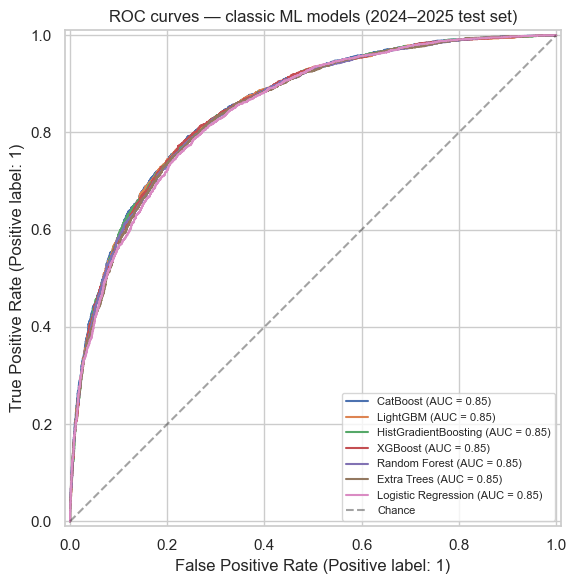

Saved C:\Users\test\Desktop\2007-2025 datasets (.csv, .dta)\exploration_outputs\ml_model_comparison.csv
                         model      auc  accuracy       f1  val_auc family
                FT-Transformer 0.864000  0.787200 0.778000      NaN     DL
                TabTransformer 0.863600  0.787600 0.769100      NaN     DL
                         DCNv2 0.862700  0.781600 0.767000      NaN     DL
                    ResNet-MLP 0.858700  0.779300 0.764600      NaN     DL
Logistic Regression (baseline) 0.857300  0.783000 0.772200      NaN     DL
                      CatBoost 0.854935  0.772448 0.751929 0.865934     ML
                      LightGBM 0.852761  0.772920 0.752485 0.862916     ML
          HistGradientBoosting 0.852214  0.772291 0.740316 0.862570     ML
                       XGBoost 0.852081  0.774336 0.754155 0.862051     ML
                        TabNet 0.852000  0.781200 0.761500      NaN     DL
                 Random Forest 0.849982  0.769932 0.747628 0.862123    

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
for name in comparison["model"]:
    RocCurveDisplay.from_predictions(y_test, test_probas[name], name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.4, label="Chance")
ax.set_title("ROC curves — classic ML models (2024–2025 test set)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

out_path = OUTPUT_DIR / "ml_model_comparison.csv"
comparison.to_csv(out_path, index=False)
print(f"Saved {out_path}")

dl_path = OUTPUT_DIR / "dl_model_comparison.csv"
if dl_path.exists():
    dl = pd.read_csv(dl_path, index_col=0).reset_index().rename(columns={"index": "model"})
    combined = pd.concat([
        comparison.assign(family="ML"),
        dl.assign(family="DL"),
    ], ignore_index=True).sort_values("auc", ascending=False)
    print(combined.head(12).to_string(index=False))
    combined.to_csv(OUTPUT_DIR / "all_model_comparison.csv", index=False)
    print(f"Saved {OUTPUT_DIR / 'all_model_comparison.csv'}")

In [8]:
best_name = comparison.iloc[0]["model"]
best_pipe = dict(MODELS)[best_name]
best_pred = (test_probas[best_name] >= 0.5).astype(int)
print(f"Best model: {best_name}\n")
print(classification_report(y_test, best_pred, target_names=["no dep/anx", "elevated dep/anx"]))

Best model: CatBoost

                  precision    recall  f1-score   support

      no dep/anx       0.80      0.78      0.79      3502
elevated dep/anx       0.74      0.77      0.75      2857

        accuracy                           0.77      6359
       macro avg       0.77      0.77      0.77      6359
    weighted avg       0.77      0.77      0.77      6359

